In [58]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [59]:
exoplanet_data = pd.read_csv("exoplanet_data.csv", comment = "#")

In [60]:
exoplanet_data.shape 
# There are 597 rows and 92 columns

(597, 92)

In [61]:
print(exoplanet_data.columns)
# I have no idea what ttv_flag, pl_radj, pl_insol, pl_eqt, and st_logg mean. 

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

In [62]:
# Planet Name (pl_name): The name of the exoplanet
# Host Name (hostname) The name of the exoplanet's host star
# Discovery Method (discoverymethod): How the exoplanet was discovered
# Spectral Type (st_spectype): The spectral type of the host star
# Equilibrium Temperature [K] (pl_eqt): The theoretical temperature of the exoplanet as a perfect blackbody
# Planet Mass or Mass*sin(i) [Jupiter Mass] (pl_bmassj): The mass of the exoplanet in terms of Jupiter masses

In [63]:
exoplanet_data.value_counts("discoverymethod")

discoverymethod
Transit                      403
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64

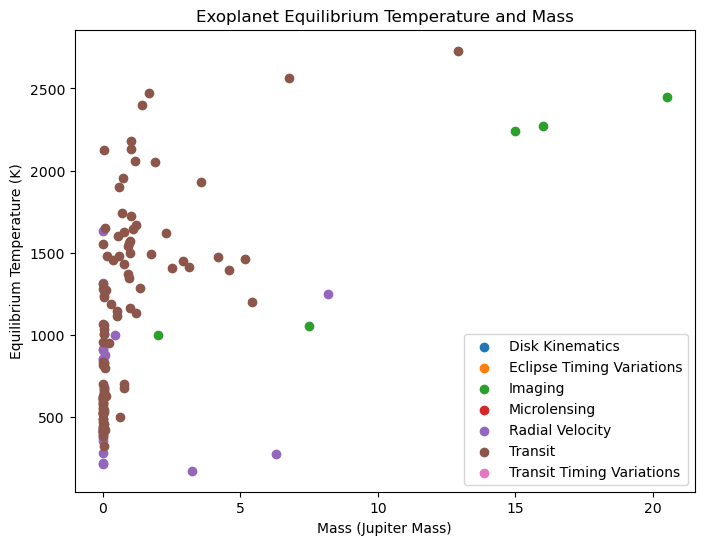

In [64]:
plt.figure(figsize = (8, 6))

for method, group in exoplanet_data.groupby("discoverymethod"):
    plt.scatter(group["pl_bmassj"], group["pl_eqt"], label = method)

plt.title("Exoplanet Equilibrium Temperature and Mass")
plt.xlabel("Mass (Jupiter Mass)")
plt.ylabel("Equilibrium Temperature (K)")
plt.legend()

plt.show()

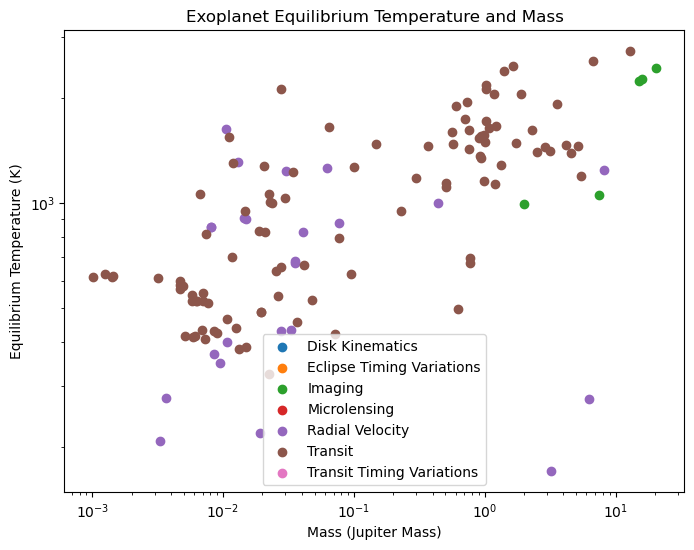

In [65]:
plt.figure(figsize = (8, 6))
plt.yscale("log")
plt.xscale("log")

for method, group in exoplanet_data.groupby("discoverymethod"):
    plt.scatter(group["pl_bmassj"], group["pl_eqt"], label = method)

plt.title("Exoplanet Equilibrium Temperature and Mass")
plt.xlabel("Mass (Jupiter Mass)")
plt.ylabel("Equilibrium Temperature (K)")
plt.legend()

plt.show()

In [66]:
# Based on the plot, exoplanets found using imaging are more likely to be massive.

In [93]:
massive_planets = exoplanet_data[exoplanet_data["pl_bmassj"] > 5]
coldest_row = massive_planets.loc[massive_planets["pl_eqt"].idxmin()]

coldest_row = pd.DataFrame(coldest_row)
coldest_row = coldest_row.T
coldest_row

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
593,eps Ind A b,eps Ind A,0,3,1,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,2.237,0.24,-0.24,4.34562,0.007374,-0.007374,2024-08-07,2024-09,2024-08-07


In [95]:
print(coldest_row["pl_eqt"])
print(coldest_row["pl_bmassj"])
print(coldest_row["st_spectype"])

593    275.0
Name: pl_eqt, dtype: object
593    6.31
Name: pl_bmassj, dtype: object
593    K5 V
Name: st_spectype, dtype: object


In [96]:
# The planet's name is eps Ind A b. It is at index 593. 
# It's equilibrium temperature is 275.0. It's mass is 0.6.31 Jupiter masses.
# The star it is orbiting has a spectral type K5 V. Our sun is a G-type star, so it is not a sun-like star. 

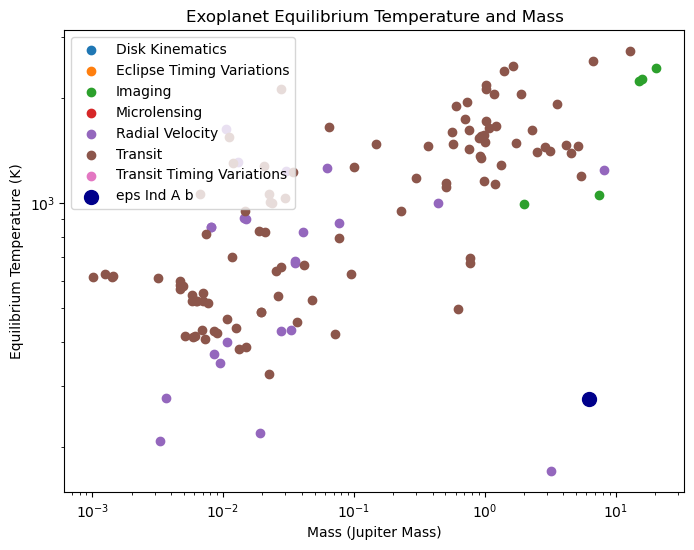

In [107]:
plt.figure(figsize = (8, 6))
plt.yscale("log")
plt.xscale("log")

for method, group in exoplanet_data.groupby("discoverymethod"):
    plt.scatter(group["pl_bmassj"], group["pl_eqt"], label = method)

plt.scatter(coldest_row["pl_bmassj"], coldest_row["pl_eqt"], label = "eps Ind A b", color = "darkblue", s = 100)

plt.title("Exoplanet Equilibrium Temperature and Mass")
plt.xlabel("Mass (Jupiter Mass)")
plt.ylabel("Equilibrium Temperature (K)")
plt.legend(loc = "upper left")

plt.show()

In [ ]:
# The title is "A temperate super-Jupiter imaged with JWST in the mid-infrared". 
# Eps Ind A is a K5V star about the same age as the sun. The exoplanet orbiting it, Eps Ind A b, is a giant exoplanet originally detected with the radial velocity method. JWST images confirmed its existence, but disagree with the properties previously assigned. Its existence supports theoretical planetary thermal evolution models that had been previously untested at this temperature range. 
# Yes, the answer matches the exoplanet. 
# This planet is special because it is a super-Jupiter with an extremely cold temperature, and is also very close to Earth. 
# The mass (6.31 Jupiter masses) and eqilibrium temperature (275K) both match what the paper reported. 